# Final benchmark charts
100 examples per task (seed 42), Qwen3.5 4B/9B/27B, non-thinking. All evaluations are cache-only: a missing response or likelihood raises an error rather than loading a model.

In [4]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
from pathlib import Path
import logging

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.metrics import f1_score

from experiment_setup.benchmarks import load_examples, sample_tasks
from experiment_setup import dc_pmi, llm_critic
from experiment_setup.logging_setup import logger

logger.setLevel(logging.ERROR)  # Avoid printing full transcripts of unparseable judge responses.
CACHE = Path('small-cache')
MODELS = {'4B': 'Qwen/Qwen3.5-4B', '9B': 'Qwen/Qwen3.5-9B', '27B': 'Qwen/Qwen3.5-27B'}
examples = sample_tasks(load_examples(), size=100, seed=42)
assert len(examples) == 1200
assert len({(e.benchmark, e.task, e.uid) for e in examples}) == len(examples)


## LLM judge
F1 measures binary error detection (not exact first-error localization) on parseable responses only. Benchmark bars pool parseable examples across task types; they are not averages of task F1 scores.

In [6]:
judge_results = {}
judge_stats = []
benchmark_f1 = []
for model, model_id in MODELS.items():
    results = llm_critic.load_run(
        examples, model_id=model_id, thinking=False,
        cache_path=CACHE / f'llm_judge_qwen35_{model.lower()}_arm.sqlite',
    )
    assert len(results) == len(examples)
    judge_results[model] = results
    task_stats = llm_critic.statistics(results)
    task_stats['model'] = model
    judge_stats.append(task_stats)
    for benchmark, group in results.groupby('benchmark', sort=False):
        valid = group[group.parse_error.isna()]
        assert len(valid), f'No parseable responses for {model}/{benchmark}'
        benchmark_f1.append({
            'model': model, 'benchmark': benchmark,
            'f1': f1_score(valid.label.notna(), valid.prediction.notna(), zero_division=0),
            'coverage': len(valid) / len(group),
        })

judge_stats = pd.concat(judge_stats, ignore_index=True)
benchmark_f1 = pd.DataFrame(benchmark_f1)
judge_table = pd.concat([
    judge_stats[['benchmark', 'task', 'model', 'f1']],
    benchmark_f1.assign(task='(all tasks)')[['benchmark', 'task', 'model', 'f1']],
], ignore_index=True).pivot(index=['benchmark', 'task'], columns='model', values='f1')
display(judge_table.reindex(columns=MODELS).round(3))
display(benchmark_f1.pivot(index='benchmark', columns='model', values='coverage').reindex(columns=MODELS).round(3).rename_axis(columns='parse coverage / model'))


model                                           4B     9B    27B
benchmark         task                                          
BIG-Bench-Mistake (all tasks)                0.829  0.770  0.870
                  dyck_languages             0.844  0.830  0.844
                  logical_deduction          1.000  0.985  1.000
                  multistep_arithmetic       0.729  0.491  0.792
                  tracking_shuffled_objects  0.569  0.559  0.682
                  word_sorting               0.881  0.803  0.955
MR-GSM8K          (all tasks)                0.812  0.808  0.914
                  POT                        0.829  0.852  0.931
                  original                   0.826  0.737  0.889
                  reversed                   0.782  0.828  0.923
ProcessBench      (all tasks)                0.848  0.893  0.915
                  gsm8k                      0.822  0.889  0.933
                  math                       0.877  0.891  0.894
                  olympiadbench              0.830  0.857  0.889
                  omnimath                   0.860  0.930  0.942

parse coverage / model,4B,9B,27B
benchmark,,,
BIG-Bench-Mistake,0.982,0.972,1.000
MR-GSM8K,1.000,0.987,1.000
ProcessBench,0.800,1.000,0.998


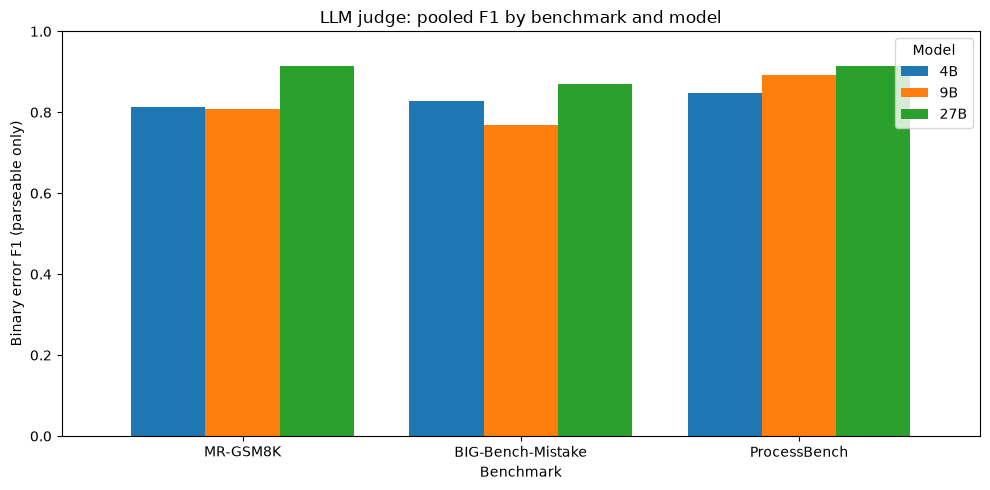

In [7]:
benchmarks = list(judge_results['4B'].benchmark.unique())
pooled_f1 = benchmark_f1.pivot(index='benchmark', columns='model', values='f1').reindex(index=benchmarks, columns=MODELS)
ax = pooled_f1.plot.bar(figsize=(10, 5), rot=0, ylim=(0, 1), width=0.8)
ax.set(xlabel='Benchmark', ylabel='Binary error F1 (parseable only)', title='LLM judge: pooled F1 by benchmark and model')
ax.legend(title='Model')
plt.tight_layout()
plt.show()


## DC-PMI
AUROC uses every step, including steps after the annotated first error. Only the first-error step is positive; all other steps are negative. For all three DC-PMI variants, **lower raw scores** predict first errors (AUROC uses negated scores). Higher perplexity predicts first errors. Each AUROC pools steps within a task type. For DC-PMI only, one-sided Mann–Whitney U p-values test whether negated scores are higher at first-error steps than at all other steps; bars with p > 0.05 are faded. Perplexity has no significance test.

In [8]:
pmi_stats = []
pmi_scores = []
pooled_pmi_f1 = []
for model, model_id in MODELS.items():
    scores = dc_pmi.load_run(
        examples, model_id=model_id,
        cache_path=CACHE / f'dc_pmi_qwen35_{model.lower()}_arm.sqlite',
    )
    assert scores[['benchmark', 'task', 'uid']].drop_duplicates().shape[0] == len(examples)
    pmi_scores.append(scores.assign(uid=model + ':' + scores.uid.astype(str)))
    summary = dc_pmi.statistics(scores)
    summary['model'] = model
    pmi_stats.append(summary)
    if model == '27B':
        for benchmark, group in scores.groupby('benchmark', sort=False):
            pooled = dc_pmi.statistics(group.assign(task='(all tasks)'))
            pooled_pmi_f1.append(pooled[['benchmark', 'metric', 'f1']])

pmi_stats = pd.concat(pmi_stats, ignore_index=True)
pooled_pmi_f1 = pd.concat(pooled_pmi_f1, ignore_index=True)
columns = pd.MultiIndex.from_product([MODELS, dc_pmi.METRICS], names=['model', 'metric'])
auc_table = pmi_stats.pivot(index=['benchmark', 'task'], columns=['model', 'metric'], values='auc')
display(auc_table.reindex(columns=columns).round(3))
p_value_table = pmi_stats.pivot(index=['benchmark', 'task'], columns=['model', 'metric'], values='p_value')
display(p_value_table.reindex(columns=columns).round(3))
f1_table = pmi_stats.pivot(index=['benchmark', 'task'], columns=['model', 'metric'], values='f1')
display(f1_table.reindex(columns=columns).round(3))
mcc_table = pmi_stats.pivot(index=['benchmark', 'task'], columns=['model', 'metric'], values='mcc')
display(mcc_table.reindex(columns=columns).round(3))


model                                               4B                        \
metric                                      perplexity dc_pmi_generic_domain   
benchmark         task                                                         
BIG-Bench-Mistake dyck_languages                 0.595                 0.503   
                  logical_deduction              0.592                 0.526   
                  multistep_arithmetic           0.537                 0.492   
                  tracking_shuffled_objects      0.556                 0.643   
                  word_sorting                   0.638                 0.467   
MR-GSM8K          POT                            0.660                 0.589   
                  original                       0.550                 0.642   
                  reversed                       0.571                 0.630   
ProcessBench      gsm8k                          0.649                 0.528   
                  math                           0.637                 0.461   
                  olympiadbench                  0.676                 0.460   
                  omnimath                       0.596                 0.483   

model                                                                 \
metric                                      dc_pmi_question_ablation   
benchmark         task                                                 
BIG-Bench-Mistake dyck_languages                               0.349   
                  logical_deduction                            0.572   
                  multistep_arithmetic                         0.243   
                  tracking_shuffled_objects                    0.093   
                  word_sorting                                 0.425   
MR-GSM8K          POT                                          0.401   
                  original                                     0.517   
                  reversed                                     0.445   
ProcessBench      gsm8k                                        0.484   
                  math                                         0.457   
                  olympiadbench                                0.308   
                  omnimath                                     0.289   

model                                                                \
metric                                      dc_pmi_history_ablation   
benchmark         task                                                
BIG-Bench-Mistake dyck_languages                              0.457   
                  logical_deduction                           0.461   
                  multistep_arithmetic                        0.549   
                  tracking_shuffled_objects                   0.490   
                  word_sorting                                0.428   
MR-GSM8K          POT                                         0.513   
                  original                                    0.474   
                  reversed                                    0.520   
ProcessBench      gsm8k                                       0.466   
                  math                                        0.412   
                  olympiadbench                               0.438   
                  omnimath                                    0.451   

model                                               9B                        \
metric                                      perplexity dc_pmi_generic_domain   
benchmark         task                                                         
BIG-Bench-Mistake dyck_languages                 0.609                 0.462   
                  logical_deduction              0.598                 0.539   
                  multistep_arithmetic           0.523                 0.533   
                  tracking_shuffled_objects      0.546                 0.625   
                  word_sorting                   0.655                 0.460   
MR-GSM8K    

model                                               4B                        \
metric                                      perplexity dc_pmi_generic_domain   
benchmark         task                                                         
BIG-Bench-Mistake dyck_languages                 0.006                 0.937   
                  logical_deduction              0.003                 0.405   
                  multistep_arithmetic           0.303                 0.823   
                  tracking_shuffled_objects      0.102                 0.000   
                  word_sorting                   0.000                 0.300   
MR-GSM8K          POT                            0.000                 0.041   
                  original                       0.217                 0.000   
                  reversed                       0.086                 0.002   
ProcessBench      gsm8k                          0.000                 0.501   
                  math                           0.000                 0.301   
                  olympiadbench                  0.000                 0.282   
                  omnimath                       0.006                 0.633   

model                                                                 \
metric                                      dc_pmi_question_ablation   
benchmark         task                                                 
BIG-Bench-Mistake dyck_languages                               0.000   
                  logical_deduction                            0.021   
                  multistep_arithmetic                         0.000   
                  tracking_shuffled_objects                    0.000   
                  word_sorting                                 0.020   
MR-GSM8K          POT                                          0.023   
                  original                                     0.674   
                  reversed                                     0.186   
ProcessBench      gsm8k                                        0.707   
                  math                                         0.265   
                  olympiadbench                                0.000   
                  omnimath                                     0.000   

model                                                                \
metric                                      dc_pmi_history_ablation   
benchmark         task                                                
BIG-Bench-Mistake dyck_languages                              0.205   
                  logical_deduction                           0.203   
                  multistep_arithmetic                        0.167   
                  tracking_shuffled_objects                   0.780   
                  word_sorting                                0.024   
MR-GSM8K          POT                                         0.764   
                  original                                    0.523   
                  reversed                                    0.624   
ProcessBench      gsm8k                                       0.420   
                  math                                        0.020   
                  olympiadbench                               0.100   
                  omnimath                                    0.165   

model                                               9B                        \
metric                                      perplexity dc_pmi_generic_domain   
benchmark         task                                                         
BIG-Bench-Mistake dyck_languages                 0.002                 0.271   
                  logical_deduction              0.002                 0.209   
                  multistep_arithmetic           0.521                 0.349   
                  tracking_shuffled_objects      0.187                 0.000   
                  word_sorting                   0.000                 0.206   
MR-GSM8K    

model                                               4B                        \
metric                                      perplexity dc_pmi_generic_domain   
benchmark         task                                                         
BIG-Bench-Mistake dyck_languages                 0.105                 0.064   
                  logical_deduction              0.276                 0.252   
                  multistep_arithmetic           0.335                 0.290   
                  tracking_shuffled_objects      0.400                 0.377   
                  word_sorting                   0.195                 0.147   
MR-GSM8K          POT                            0.198                 0.180   
                  original                       0.186                 0.204   
                  reversed                       0.100                 0.212   
ProcessBench      gsm8k                          0.253                 0.206   
                  math                           0.246                 0.187   
                  olympiadbench                  0.204                 0.133   
                  omnimath                       0.206                 0.171   

model                                                                 \
metric                                      dc_pmi_question_ablation   
benchmark         task                                                 
BIG-Bench-Mistake dyck_languages                               0.232   
                  logical_deduction                            0.222   
                  multistep_arithmetic                         0.444   
                  tracking_shuffled_objects                    0.635   
                  word_sorting                                 0.153   
MR-GSM8K          POT                                          0.230   
                  original                                     0.218   
                  reversed                                     0.205   
ProcessBench      gsm8k                                        0.253   
                  math                                         0.222   
                  olympiadbench                                0.288   
                  omnimath                                     0.311   

model                                                                \
metric                                      dc_pmi_history_ablation   
benchmark         task                                                
BIG-Bench-Mistake dyck_languages                              0.063   
                  logical_deduction                           0.248   
                  multistep_arithmetic                        0.333   
                  tracking_shuffled_objects                   0.324   
                  word_sorting                                0.153   
MR-GSM8K          POT                                         0.149   
                  original                                    0.145   
                  reversed                                    0.125   
ProcessBench      gsm8k                                       0.189   
                  math                                        0.186   
                  olympiadbench                               0.134   
                  omnimath                                    0.172   

model                                               9B                        \
metric                                      perplexity dc_pmi_generic_domain   
benchmark         task                                                         
BIG-Bench-Mistake dyck_languages                 0.107                 0.062   
                  logical_deduction              0.295                 0.254   
                  multistep_arithmetic           0.342                 0.296   
                  tracking_shuffled_objects      0.401                 0.370   
                  word_sorting                   0.211                 0.147   
MR-GSM8K    

model                                               4B                        \
metric                                      perplexity dc_pmi_generic_domain   
benchmark         task                                                         
BIG-Bench-Mistake dyck_languages                 0.114                 0.066   
                  logical_deduction              0.166                 0.151   
                  multistep_arithmetic           0.222                 0.089   
                  tracking_shuffled_objects      0.322                 0.242   
                  word_sorting                   0.157                 0.050   
MR-GSM8K          POT                            0.129                 0.103   
                  original                       0.128                 0.174   
                  reversed                       0.063                 0.176   
ProcessBench      gsm8k                          0.146                 0.094   
                  math                           0.144                 0.029   
                  olympiadbench                  0.158                 0.075   
                  omnimath                       0.117                 0.064   

model                                                                 \
metric                                      dc_pmi_question_ablation   
benchmark         task                                                 
BIG-Bench-Mistake dyck_languages                               0.211   
                  logical_deduction                            0.094   
                  multistep_arithmetic                         0.327   
                  tracking_shuffled_objects                    0.583   
                  word_sorting                                 0.128   
MR-GSM8K          POT                                          0.199   
                  original                                     0.196   
                  reversed                                     0.167   
ProcessBench      gsm8k                                        0.178   
                  math                                         0.119   
                  olympiadbench                                0.238   
                  omnimath                                     0.235   

model                                                                \
metric                                      dc_pmi_history_ablation   
benchmark         task                                                
BIG-Bench-Mistake dyck_languages                              0.061   
                  logical_deduction                           0.142   
                  multistep_arithmetic                        0.219   
                  tracking_shuffled_objects                   0.209   
                  word_sorting                                0.091   
MR-GSM8K          POT                                         0.056   
                  original                                    0.027   
                  reversed                                    0.136   
ProcessBench      gsm8k                                       0.058   
                  math                                        0.000   
                  olympiadbench                               0.016   
                  omnimath                                    0.055   

model                                               9B                        \
metric                                      perplexity dc_pmi_generic_domain   
benchmark         task                                                         
BIG-Bench-Mistake dyck_languages                 0.122                 0.055   
                  logical_deduction              0.201                 0.157   
                  multistep_arithmetic           0.231                 0.101   
                  tracking_shuffled_objects      0.314                 0.231   
                  word_sorting                   0.212                 0.050   
MR-GSM8K    

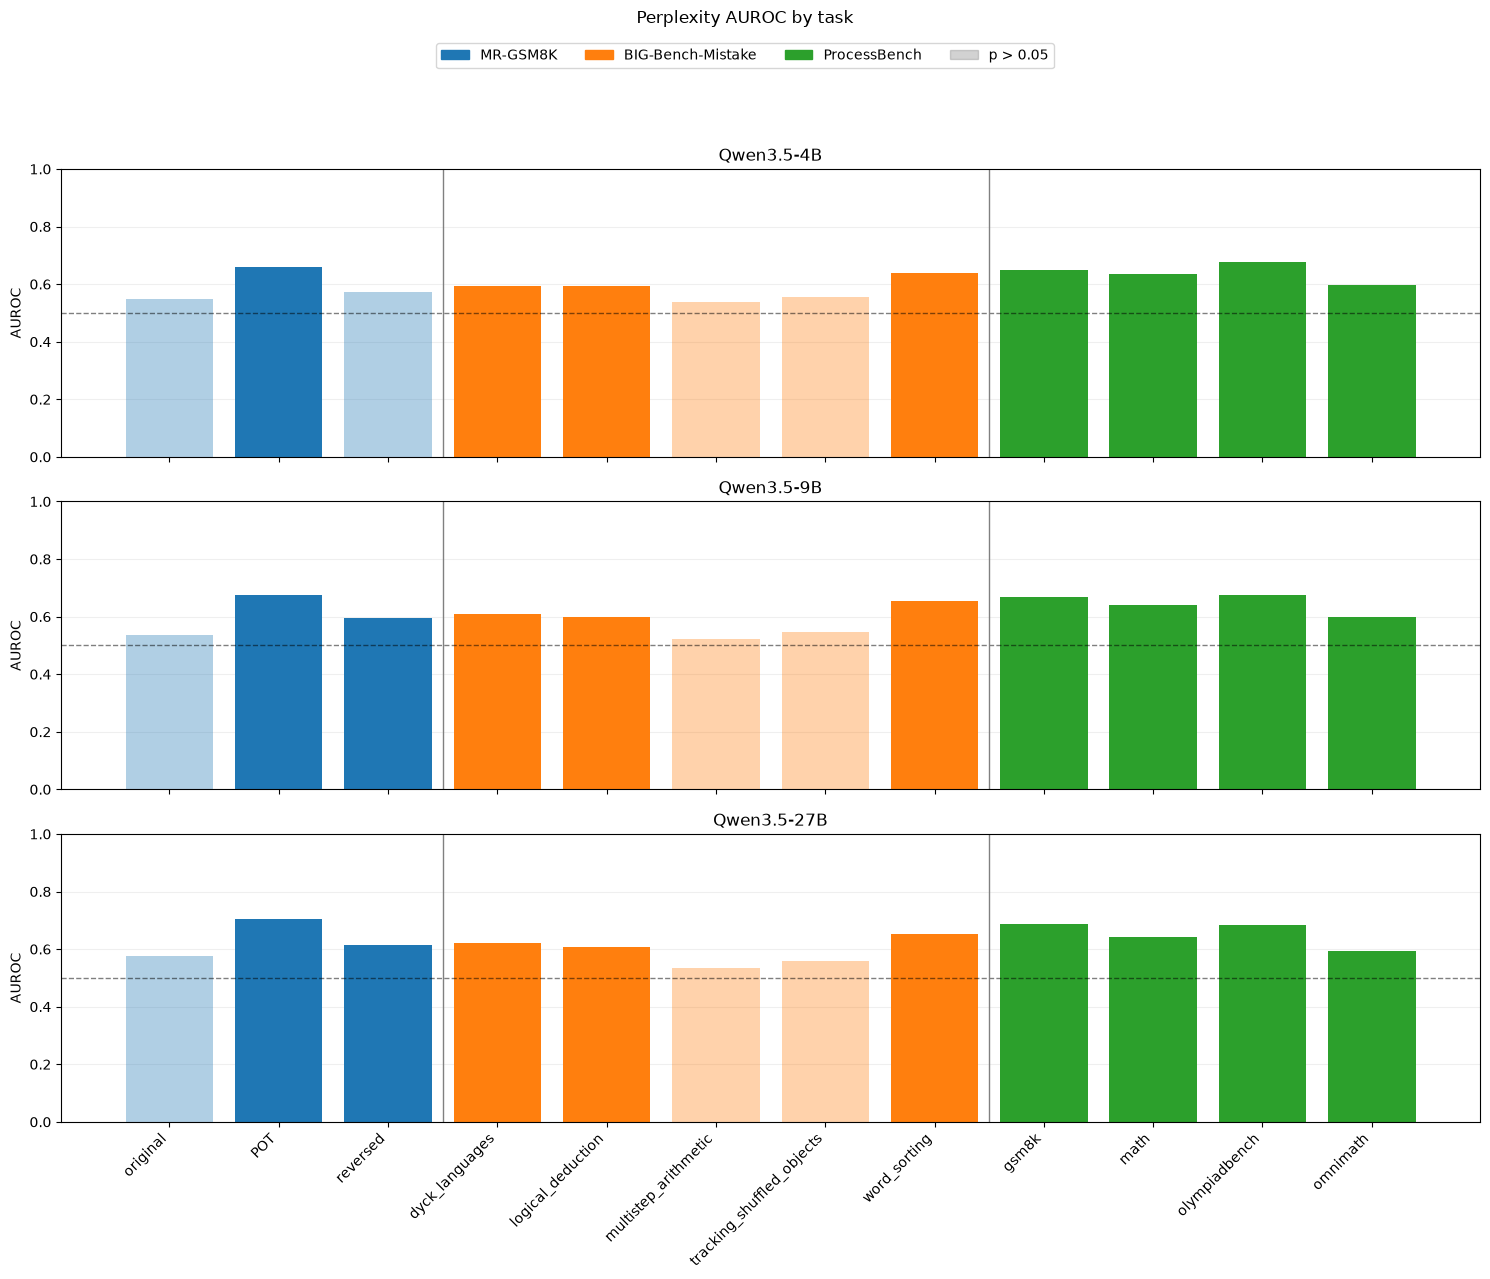

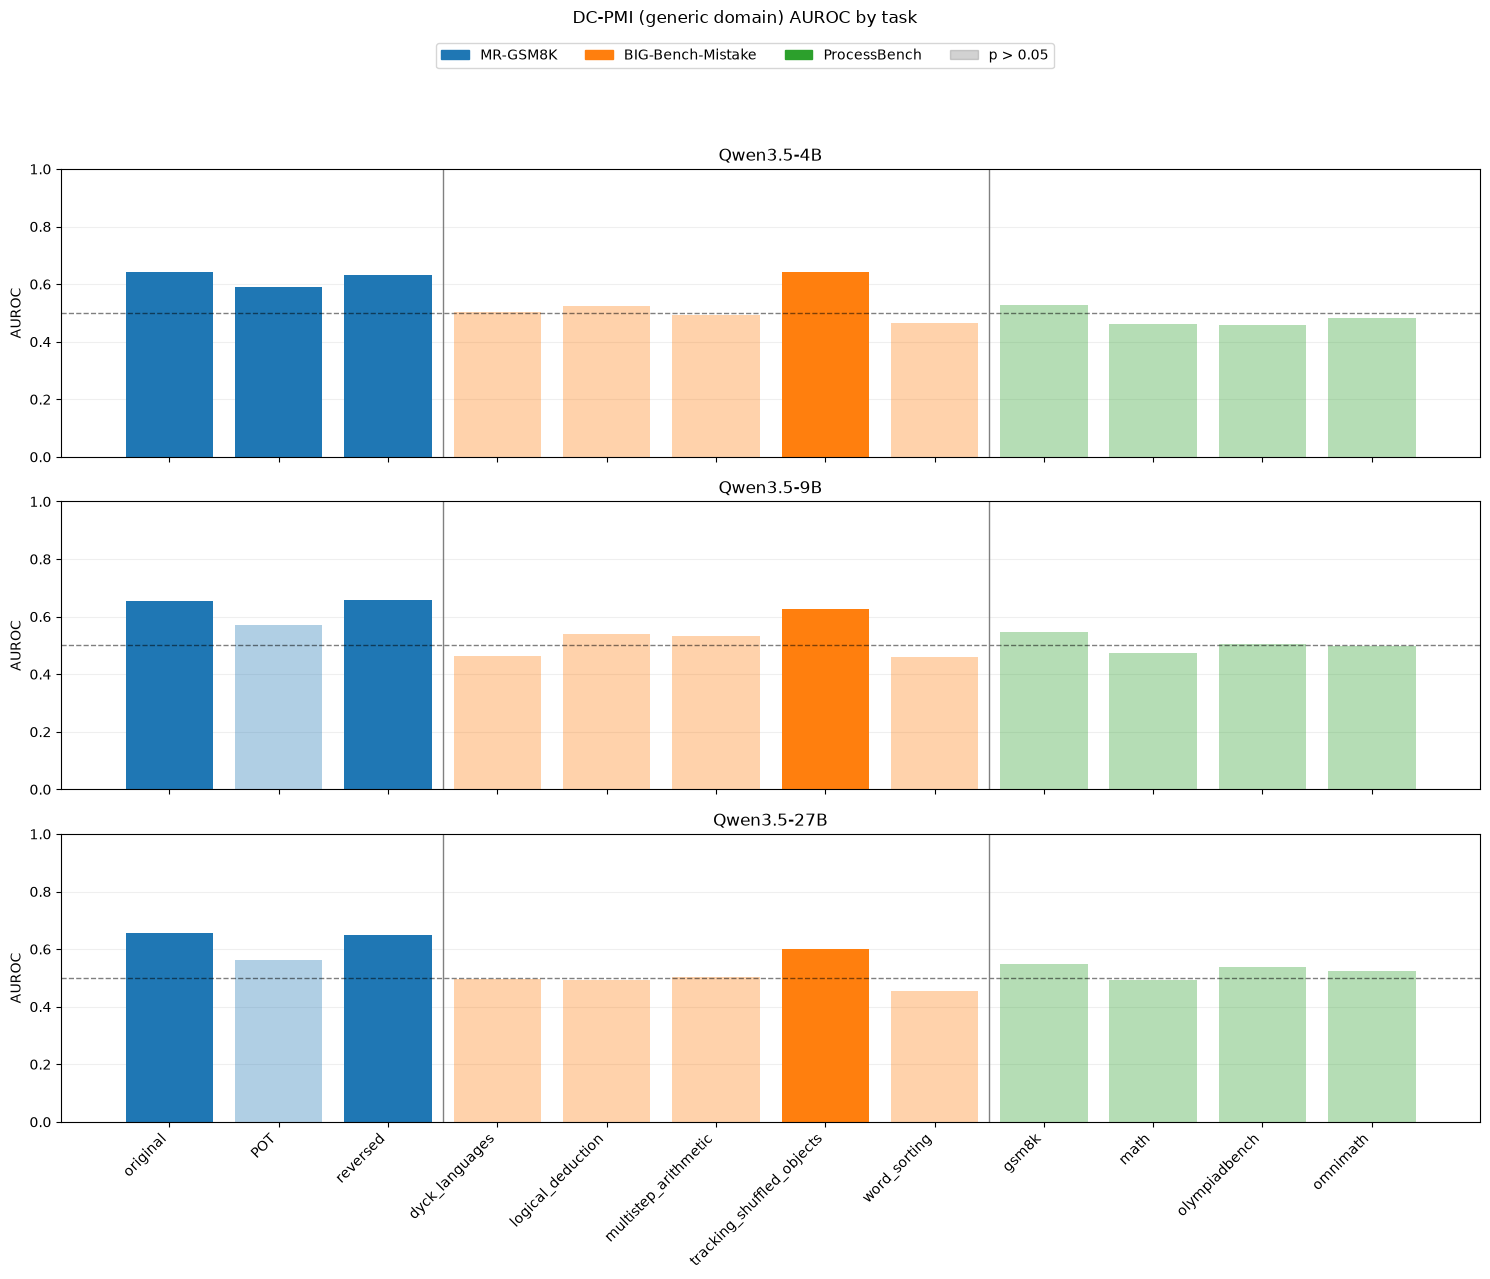

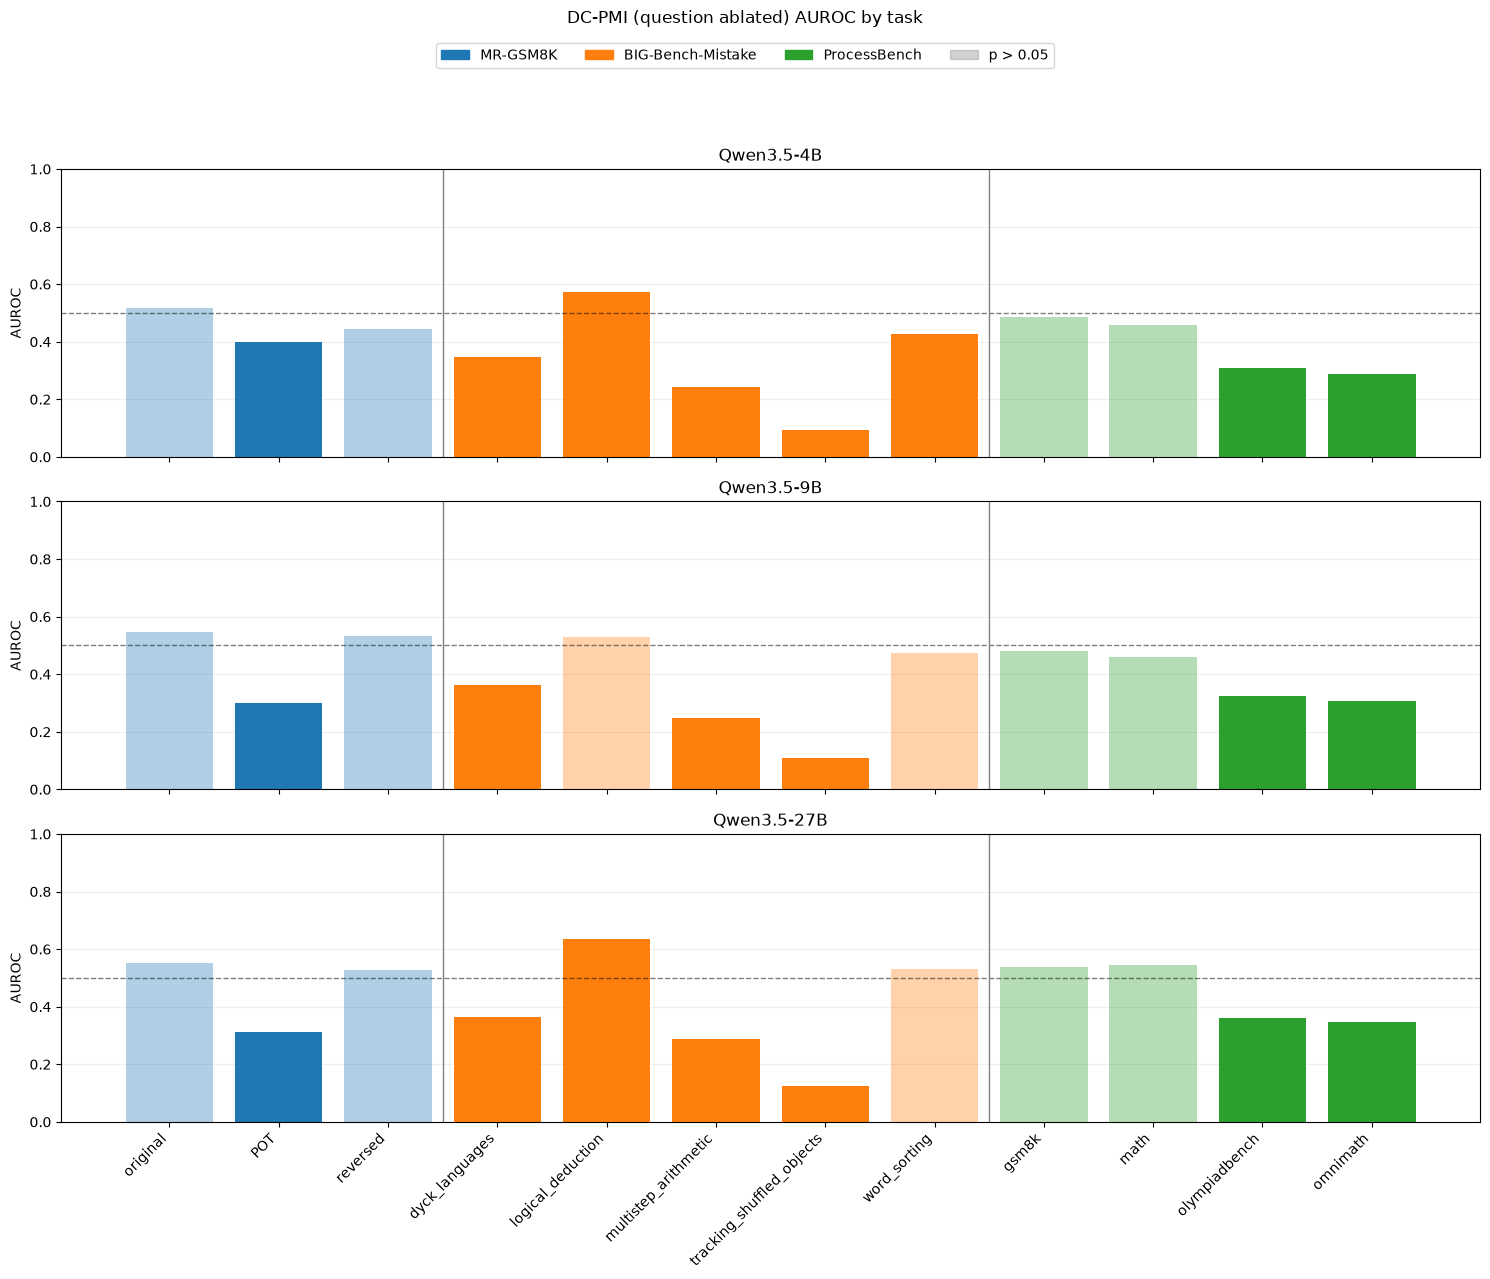

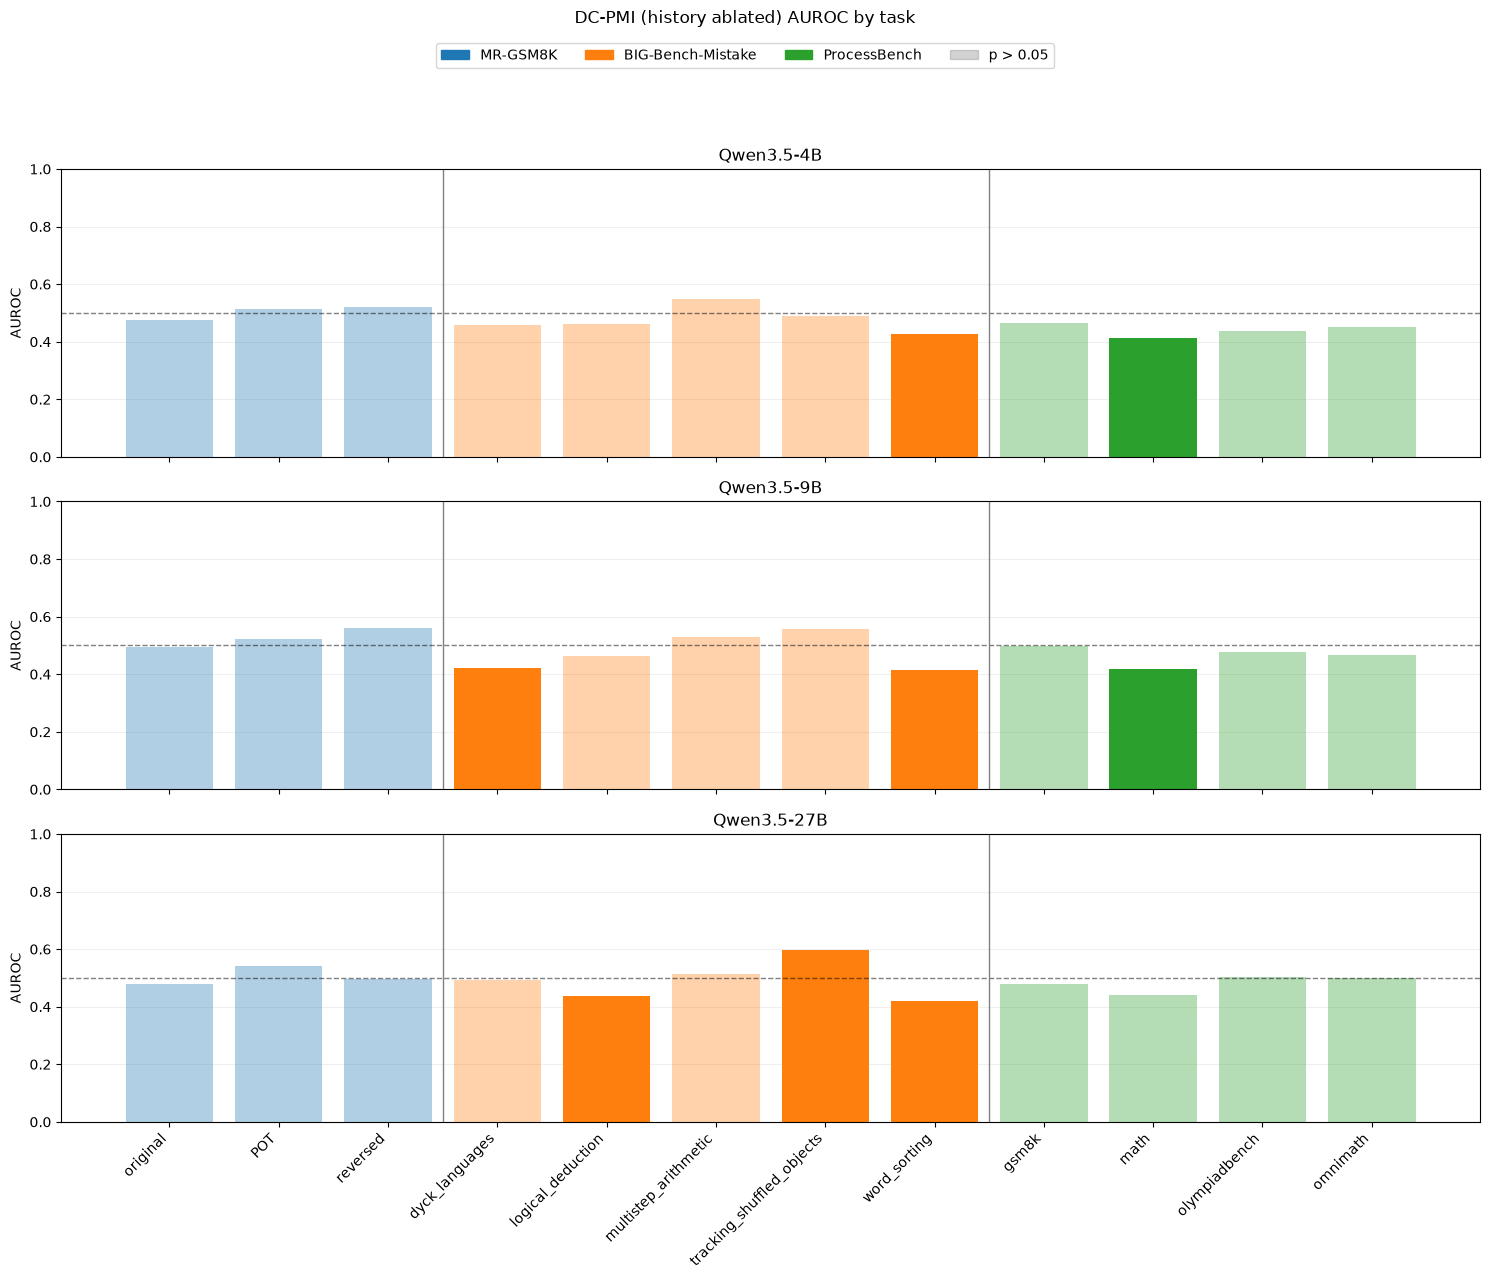

In [9]:
from experiment_setup.plots import plot_task_auc_bars

for metric in dc_pmi.METRICS:
    fig = plot_task_auc_bars(pmi_stats, metric, MODELS)
    display(fig)
    plt.close(fig)


## 27B: binary first-error F1 by benchmark

Each bar pools all task types within a benchmark. High perplexity and low question-ablated DC-PMI predict first errors. Their thresholds are tuned and evaluated on the same labeled steps (optimistic in-sample F1); the judge uses only parseable responses and predicts whether a trace contains an error, so its F1 is not directly comparable to step-level detection.


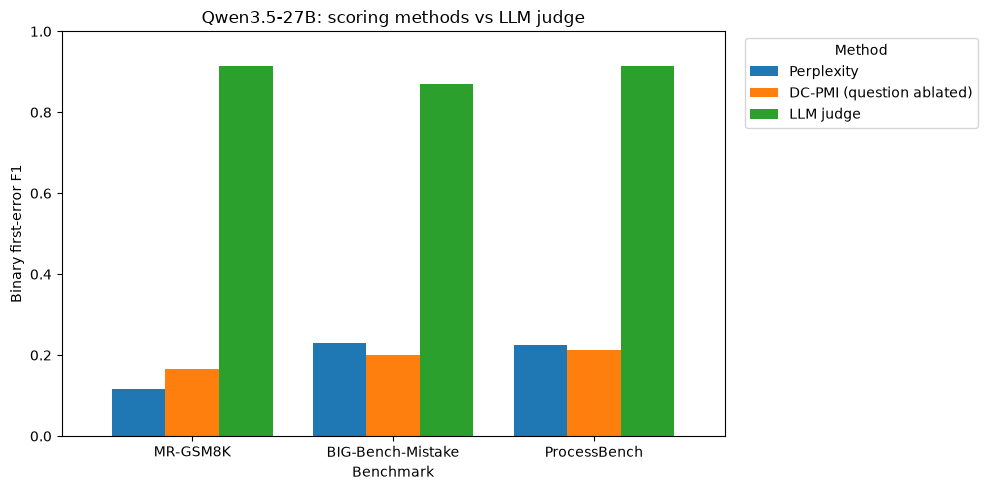

In [10]:
from experiment_setup.plots import METRIC_LABELS

chart_metrics = ('perplexity', 'dc_pmi_question_ablation')
comparison = pooled_pmi_f1.loc[pooled_pmi_f1.metric.isin(chart_metrics)].assign(
    method=lambda table: table.metric.map(METRIC_LABELS),
)[['benchmark', 'method', 'f1']]
comparison = pd.concat([
    comparison,
    benchmark_f1.loc[benchmark_f1.model == '27B', ['benchmark', 'f1']].assign(method='LLM judge'),
], ignore_index=True)
methods = [METRIC_LABELS[metric] for metric in chart_metrics] + ['LLM judge']
chart = comparison.pivot(index='benchmark', columns='method', values='f1').reindex(
    index=benchmarks, columns=methods,
)
assert chart.notna().all().all()
ax = chart.plot.bar(figsize=(10, 5), rot=0, ylim=(0, 1), width=0.8)
ax.set(xlabel='Benchmark', ylabel='Binary first-error F1', title='Qwen3.5-27B: scoring methods vs LLM judge')
ax.legend(title='Method', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


## 27B: first-error AUROC by benchmark

AUROC pools all steps across task types within each benchmark. Lower question-ablated DC-PMI and higher perplexity predict first errors.

In [ ]:
from sklearn.metrics import roc_auc_score

scores_27b = pmi_scores[list(MODELS).index('27B')]
auc_rows = []
for benchmark, group in scores_27b.groupby('benchmark', sort=False):
    assert group.first_error.nunique() == 2
    for metric in ('perplexity', 'dc_pmi_question_ablation'):
        auc_rows.append({
            'benchmark': benchmark, 'method': METRIC_LABELS[metric],
            'auroc': roc_auc_score(group.first_error, dc_pmi.error_evidence_score(group, metric)),
        })
auc_comparison = pd.DataFrame(auc_rows).pivot(index='benchmark', columns='method', values='auroc')
ax = auc_comparison.reindex(index=benchmarks, columns=[
    METRIC_LABELS['perplexity'], METRIC_LABELS['dc_pmi_question_ablation'],
]).plot.bar(figsize=(10, 5), rot=0, ylim=(0, 1), width=0.8)
ax.set(xlabel='Benchmark', ylabel='First-error AUROC', title='Qwen3.5-27B: first-error AUROC by benchmark')
ax.legend(title='Method')
plt.tight_layout()
plt.show()

## Scores around matched error and control positions

Within each benchmark task, each error trace is paired with a distinct error-free trace of the same length; unmatched errors are dropped. Both groups use the error trace's annotated first-error step as step 0. Curves pool all three models and task types with 95% bootstrap confidence intervals across model–trace pairs. The dotted horizontal line marks each group's mean at step 0. Comparing the matched control trajectories with error trajectories helps distinguish error-specific patterns from background variation.

In [11]:
from experiment_setup.benchmarks import sample_control_and_error
from experiment_setup.plots import plot_first_error_trajectories

error_examples, control_examples = sample_control_and_error(examples, seed=42)
assert len(error_examples) == len(control_examples) > 0
assert all((e.benchmark, e.task, len(e.steps)) == (c.benchmark, c.task, len(c.steps))
           for e, c in zip(error_examples, control_examples))
print(f"Sampled n={len(error_examples)} traces contraining errors and n={len(control_examples)} control traces")

Sampled n=293 traces contraining errors and n=293 control traces


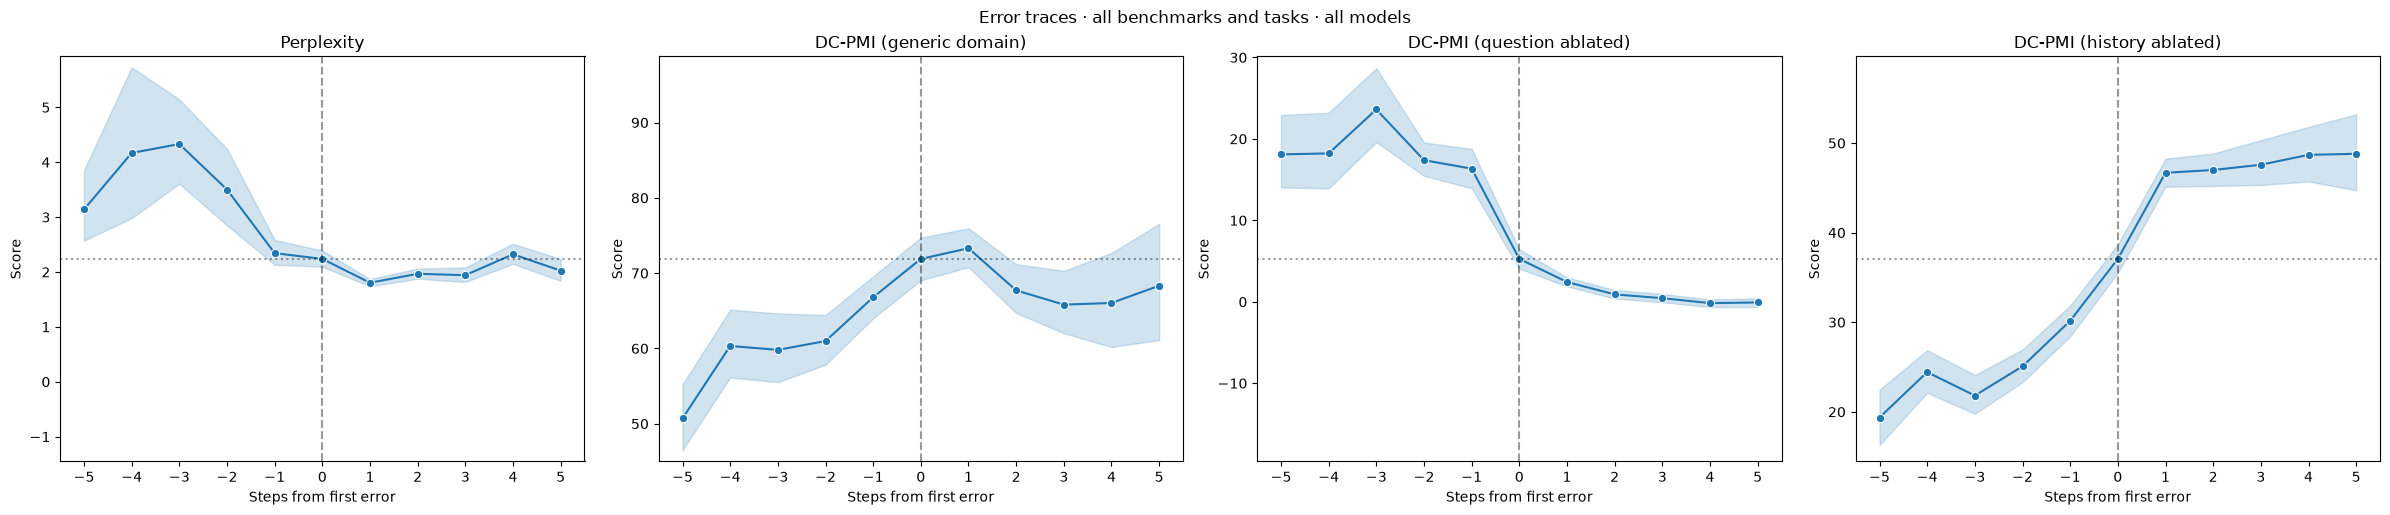

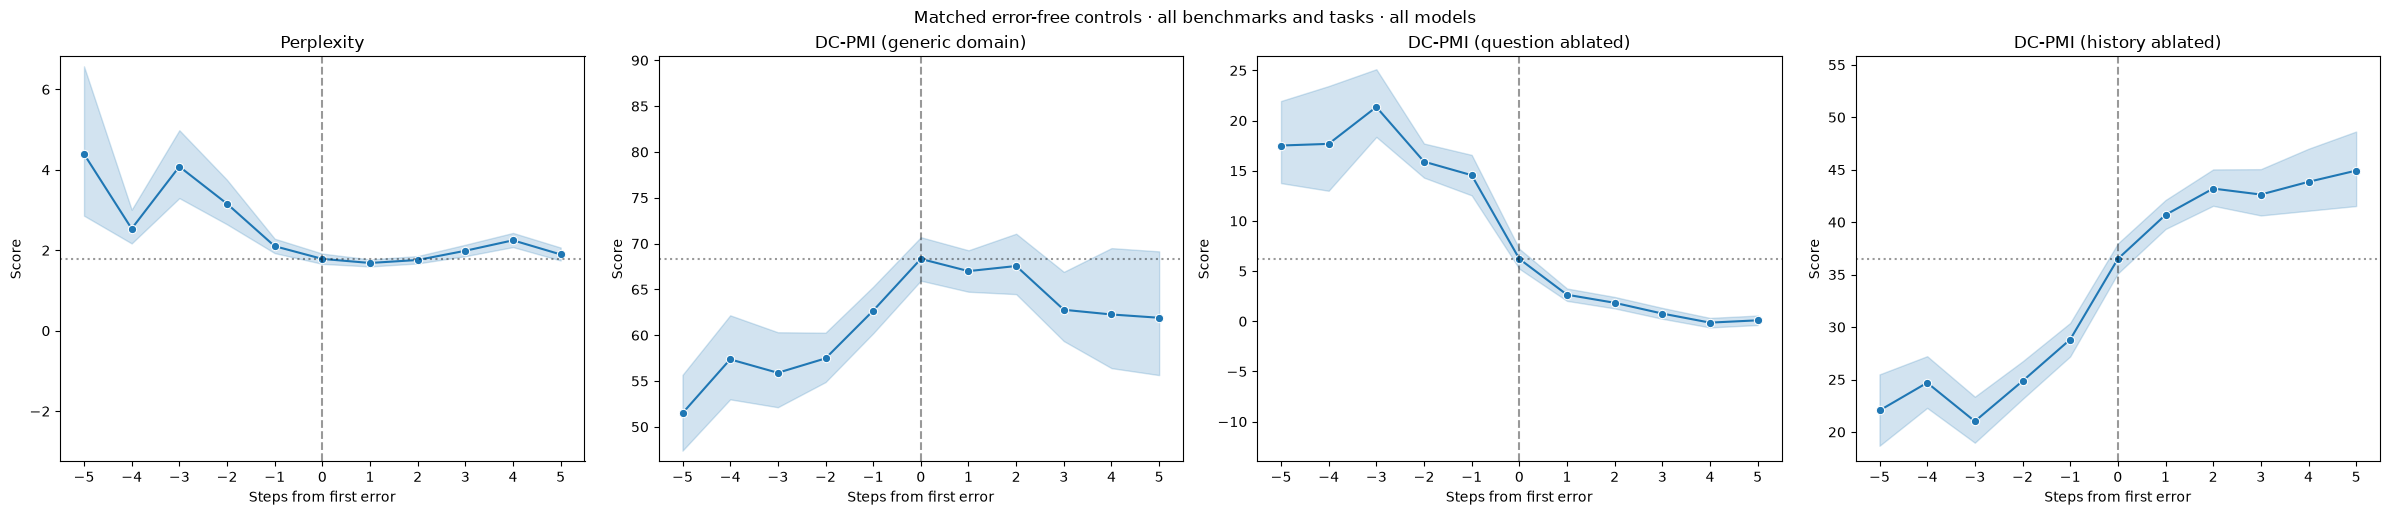

In [12]:
all_scores = pd.concat(pmi_scores, ignore_index=True)
assert all_scores[['benchmark', 'task', 'uid']].drop_duplicates().shape[0] == len(examples) * len(MODELS)
error_keys = pd.DataFrame([
    dict(benchmark=e.benchmark, task=e.task, uid=f'{model}:{e.uid}', n_steps=len(e.steps))
    for e in error_examples for model in MODELS
])
control_anchors = pd.DataFrame([
    dict(benchmark=c.benchmark, task=c.task, uid=f'{model}:{c.uid}',
         anchor=e.label, n_steps=len(c.steps))
    for e, c in zip(error_examples, control_examples) for model in MODELS
])
trace_keys = ['benchmark', 'task', 'uid']
error_scores = all_scores.merge(error_keys, on=trace_keys, how='inner', validate='many_to_one')
control_scores = all_scores.merge(control_anchors, on=trace_keys, how='inner', validate='many_to_one')
assert error_scores[trace_keys].drop_duplicates().shape[0] == len(error_examples) * len(MODELS)
assert control_scores[trace_keys].drop_duplicates().shape[0] == len(control_examples) * len(MODELS)
assert error_scores.groupby(trace_keys).size().eq(error_scores.groupby(trace_keys).n_steps.first()).all()
assert control_scores.groupby(trace_keys).size().eq(control_scores.groupby(trace_keys).n_steps.first()).all()
control_scores['first_error'] = control_scores.step.eq(control_scores.anchor)
assert control_scores.groupby(trace_keys).first_error.sum().eq(1).all()
assert error_scores.groupby(trace_keys).first_error.sum().eq(1).all()

for name, group in [('Error traces', error_scores), ('Matched error-free controls', control_scores)]:
    fig = plot_first_error_trajectories(group)
    fig.suptitle(f'{name} · all benchmarks and tasks · all models', y=1.02)
    display(fig)
    plt.close(fig)


## Scores at matched positions · 4B

Each histogram compares first-error steps with the corresponding positions in the matched error-free traces, pooled across benchmark tasks. Density normalization makes the distributions comparable.

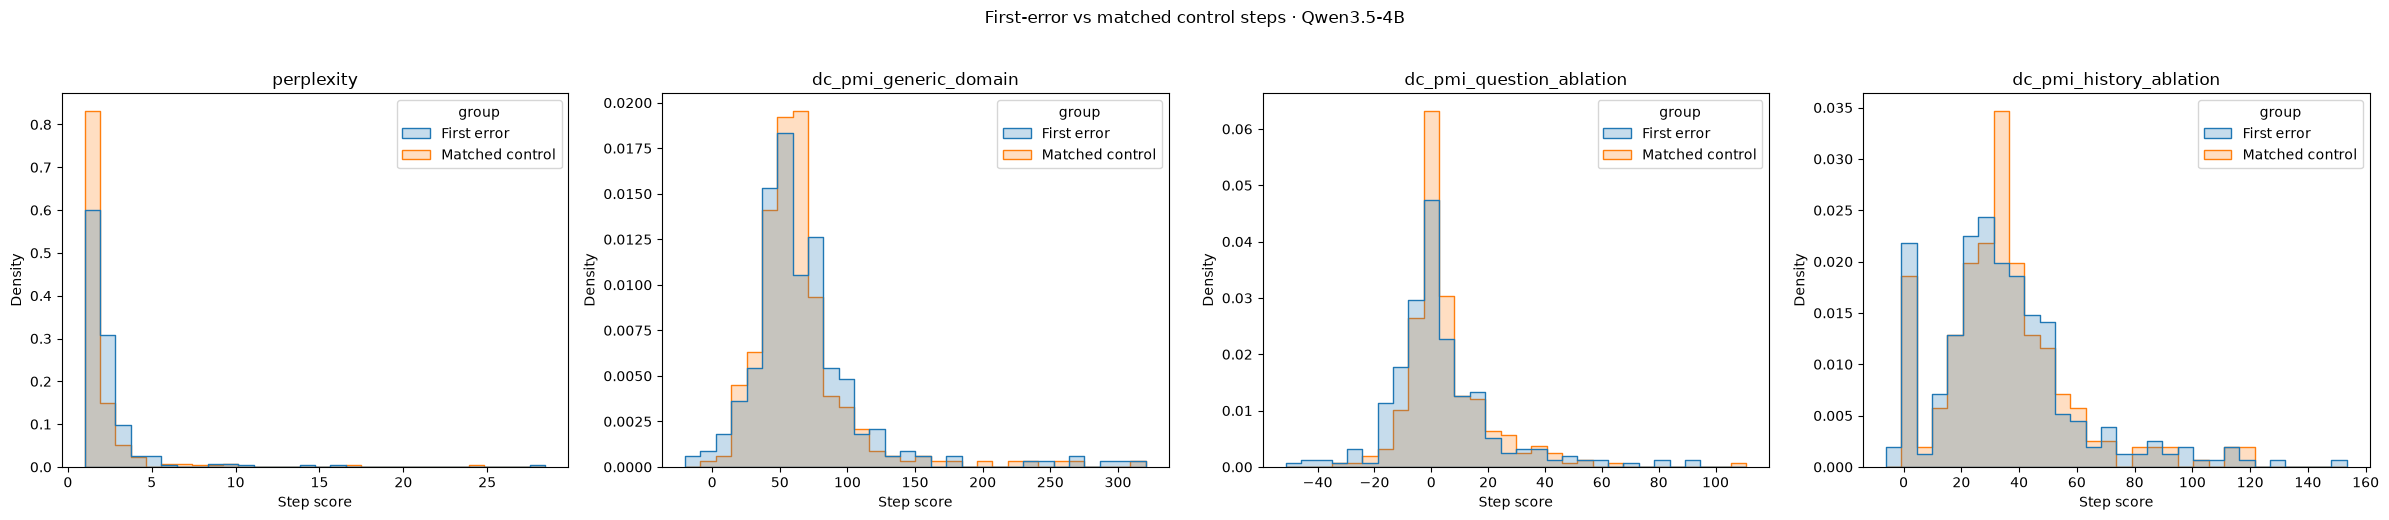

In [13]:
from experiment_setup.plots import plot_matched_step_histograms

fig = plot_matched_step_histograms(error_scores, control_scores, model='4B')
display(fig)
plt.close(fig)


## First differences at matched positions

For each metric, the step-to-step change $y_x - y_{x-1}$ is plotted separately for error traces and their matched error-free controls, using the same aligned positions as above. The first step of a trace has no preceding step, so its difference is missing.

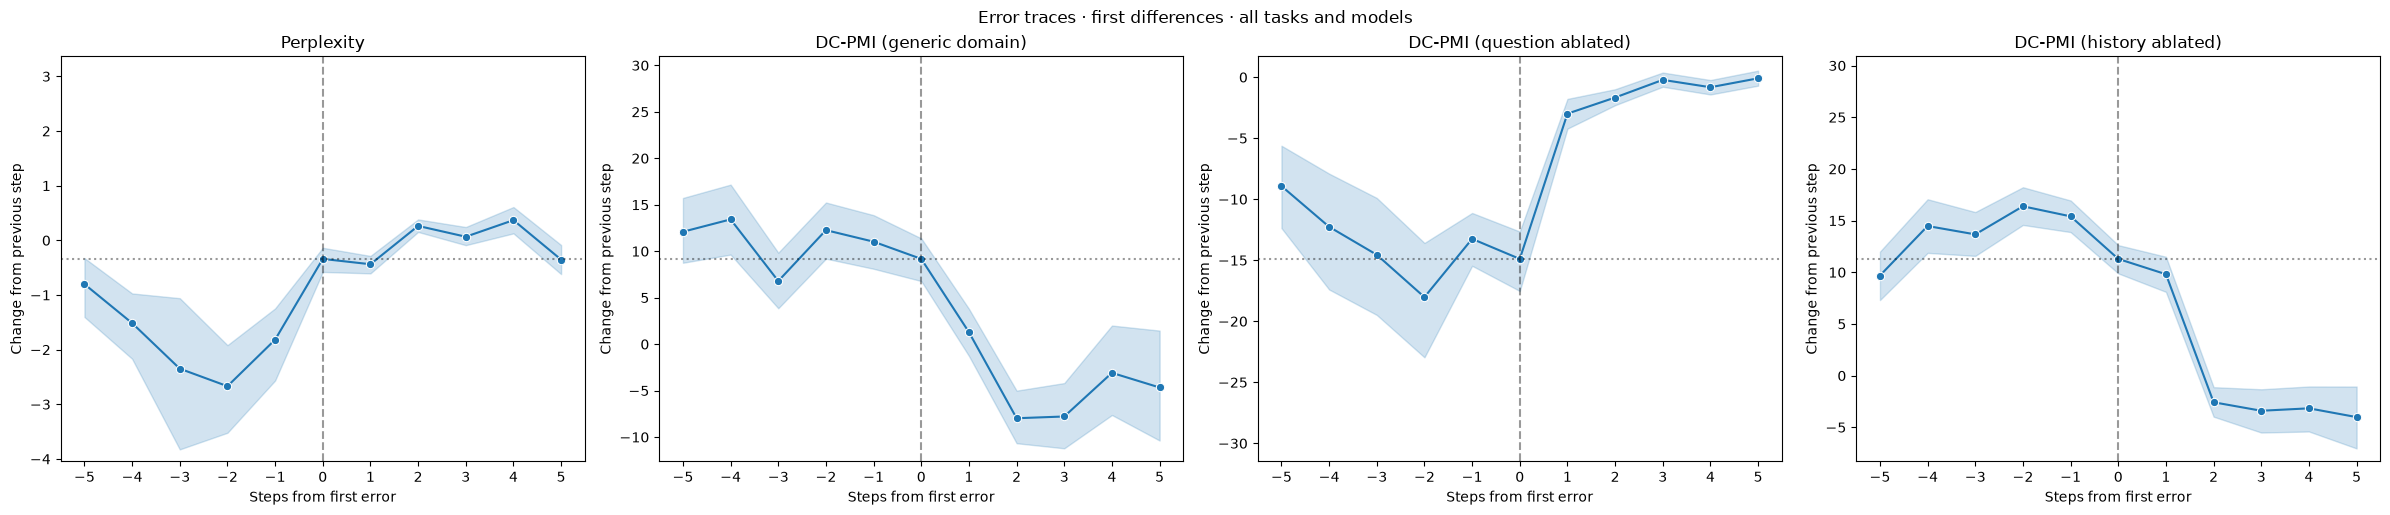

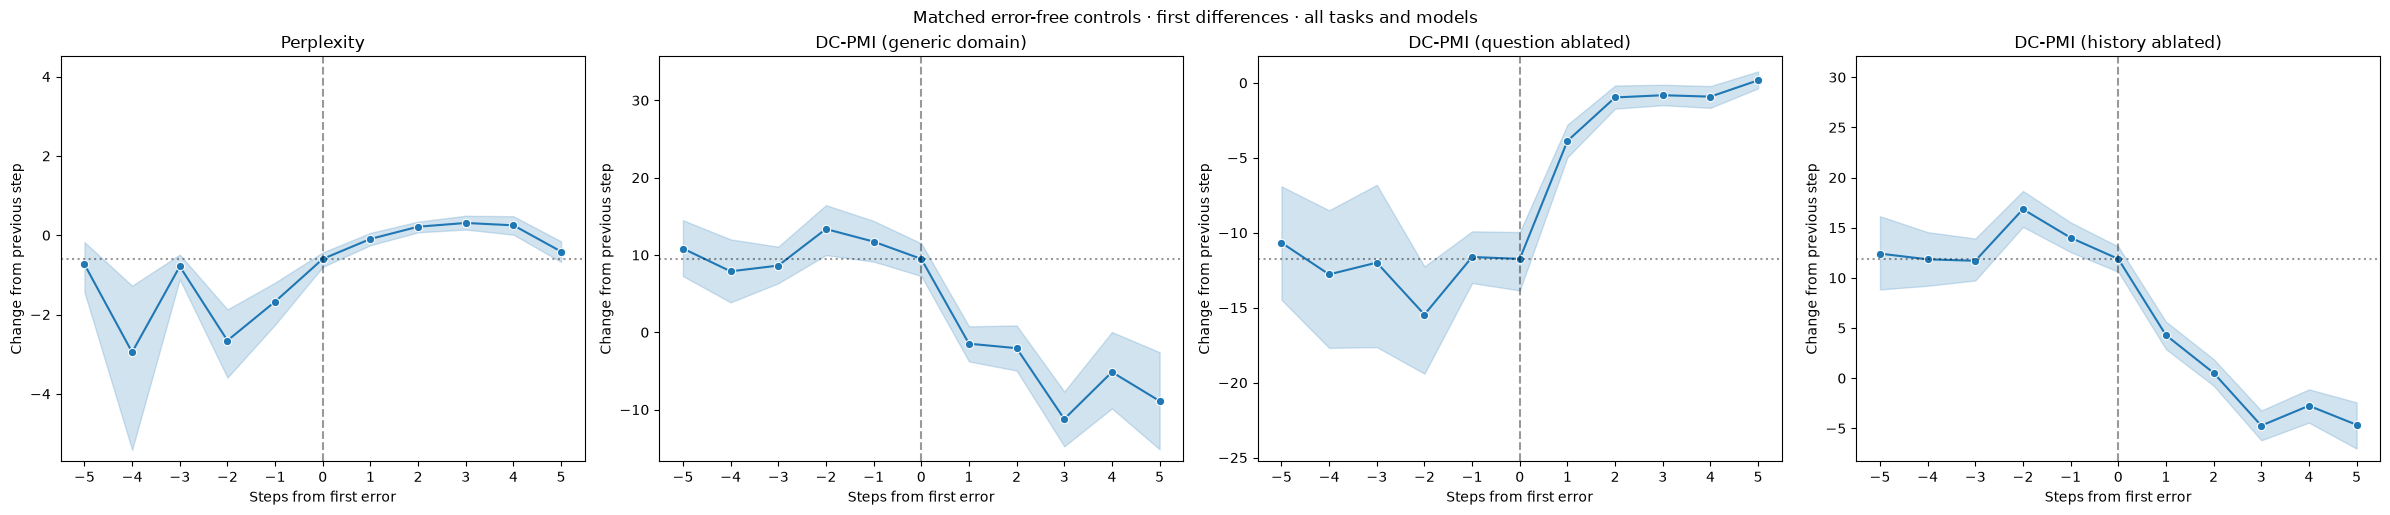

In [14]:
for name, group in [('Error traces', error_scores), ('Matched error-free controls', control_scores)]:
    difference_scores = group.sort_values(trace_keys + ['step']).copy()
    difference_scores[list(dc_pmi.METRICS)] = (
        difference_scores.groupby(trace_keys, sort=False)[list(dc_pmi.METRICS)].diff()
    )
    assert difference_scores.loc[difference_scores.step == 0, list(dc_pmi.METRICS)].isna().all().all()
    fig = plot_first_error_trajectories(difference_scores)
    for ax in fig.axes:
        ax.set_ylabel('Change from previous step')
    fig.suptitle(f'{name} · first differences · all tasks and models', y=1.02)
    display(fig)
    plt.close(fig)
